# 모델 2. 다중 선형회귀 (변수 전부)
**작성자: B**

질문: **변수를 다 넣으면?**

한계 근거: 녹지 vs 열섬 산점도(문턱 효과), VIF(다중공선성)

In [1]:
# ── 공통 설정 (모든 노트북 맨 위에 그대로 두기) ──
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/AICEE_project'   # 모두 같은 경로 (공유 폴더를 '내 드라이브에 바로가기 추가' 해야 함)
DATA = f'{BASE}/data_processed'
RESULTS = f'{BASE}/results'

import sys
sys.path.append(f'{BASE}/shared')
RANDOM_STATE = 42

USE_DUMMY = True   # ← 진짜 데이터 나오면 False로 바꾸기

Mounted at /content/drive


> **강의 규칙 (5·6주차)** — 튜닝은 교차검증 점수로만 · 전처리는 Pipeline 안에 · 바꾼 설정은 `note`에 기록 · 테스트 데이터는 C만

In [2]:
FEATURES = ['green_300', 'impervious_300', 'water_300', 'dist_han_m']   # 확정되면 팀 공통으로 수정
TARGETS = ['uhi_day', 'uhi_night']   # 낮·밤 열섬 강도

In [3]:
import pandas as pd
df = pd.read_csv(f'{DATA}/train_dummy.csv' if USE_DUMMY else f'{DATA}/train.csv')
print(df.shape); df.head()

(1100, 10)


,sensor_id,gu,lat,lon,uhi_day,uhi_night,green_300,impervious_300,water_300,dist_han_m
0,S0000,용산구,37.472749,126.900487,0.234,0.773,0.357,0.478,0.088,1898.0
1,S0001,동작구,37.491544,126.820931,0.751,0.554,0.135,0.827,0.036,377.0
2,S0002,구로구,37.477780,126.948716,0.374,0.424,0.335,0.476,0.133,3627.0
3,S0003,노원구,37.503746,127.083671,-0.155,0.708,0.249,0.710,0.023,6298.0
4,S0004,노원구,37.516282,127.088424,0.050,1.027,0.175,0.708,0.089,2601.0


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from evaluate import cv_by_district, save_cv_result, worst_sensors

X_COLS = FEATURES
NOTE = ''   # ← 설정 바꿀 때마다 적기 (6주차: 시도한 모든 설정 기록)
results = {}
for target in TARGETS:
    model = make_pipeline(StandardScaler(), LinearRegression())
    overall, per_gu, oof = cv_by_district(model, df[X_COLS], df[target], groups=df['gu'])
    save_cv_result('model2_MLR', target, overall, BASE, note=NOTE)
    results[target] = (overall, per_gu, oof)
    print(target, {k: round(v, 3) for k, v in overall.items()})

uhi_day {'RMSE': 0.51, 'MAE': 0.407, 'R2': 0.161, 'RMSE_fold_mean': 0.508, 'RMSE_fold_sd': 0.047}
uhi_night {'RMSE': 0.31, 'MAE': 0.246, 'R2': 0.657, 'RMSE_fold_mean': 0.307, 'RMSE_fold_sd': 0.035}


## 다중공선성 점검 (3주차 VIF)
녹지+불투수면+물 ≈ 100%라 VIF가 크게 나올 가능성 높음 → 계수 부호가 뒤집히거나 불안정해짐.
**VIF 10 넘으면 하나 빼고 다시 돌리기** (예: impervious 빼기) → 결정과 이유를 보고서에

In [5]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(df[FEATURES])
pd.Series([vif(Xs, i) for i in range(Xs.shape[1])], index=FEATURES).round(1)

,0
green_300,35.6
impervious_300,39.4
water_300,4.9
dist_han_m,1.0


## 표준화 계수 (3주차: 표준화하면 계수 크기를 비교 가능)

In [6]:
m = make_pipeline(StandardScaler(), LinearRegression()).fit(df[FEATURES], df['uhi_night'])
pd.Series(m[-1].coef_, index=FEATURES).round(3)   # 부호가 물리적으로 말이 되나? (녹지↑ → 시원)

,0
green_300,-0.071
impervious_300,0.369
water_300,0.046
dist_han_m,0.077


## 문턱 효과 확인 (선형회귀 한계 근거)

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44734 (\N{HANGUL SYLLABLE GGEOGG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/us

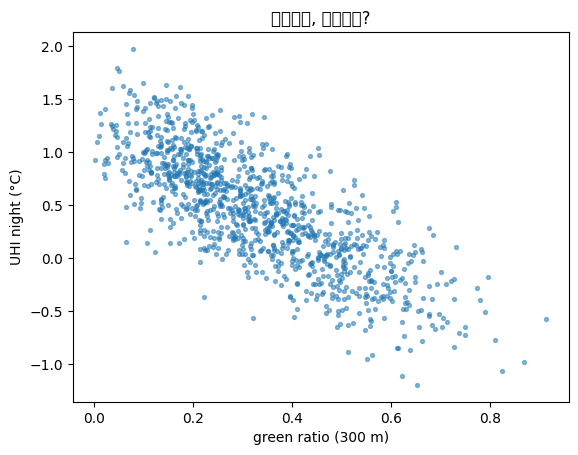

In [7]:
import matplotlib.pyplot as plt
plt.scatter(df['green_300'], df['uhi_night'], s=8, alpha=0.5)
plt.xlabel('green ratio (300 m)'); plt.ylabel('UHI night (°C)')
plt.title('직선인가, 꺾이는가?'); plt.show()

## 잔차 분석 (3주차: 잔차 그림이 정직한 검사)

/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 47924 (\N{HANGUL SYLLABLE MU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 45740 (\N{HANGUL SYLLABLE NYI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 48372 (\N{HANGUL SYLLABLE BO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_797/1771614863.py:9: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykerne

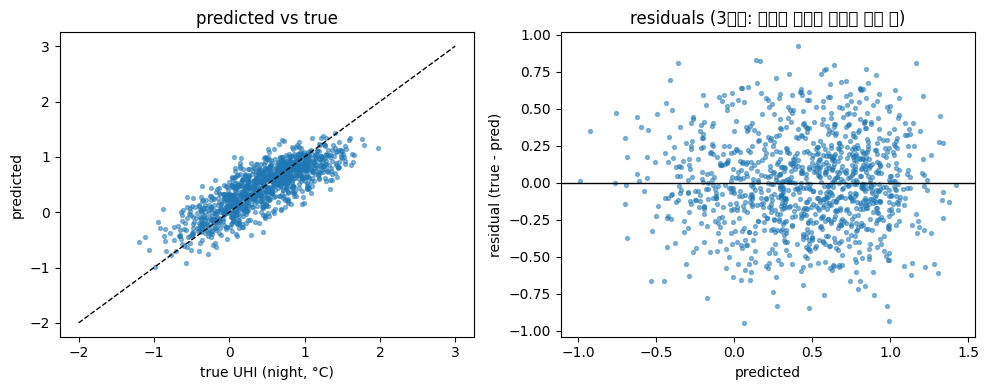

,held_out_gu,n_sensors,RMSE,MAE,R2
11,동작구,55,0.369048,0.288229,0.510135
19,영등포구,48,0.349451,0.285651,0.687802
3,강서구,42,0.348228,0.276401,0.629495
8,노원구,51,0.346778,0.281023,0.401403
15,성동구,57,0.345588,0.275718,0.526923


In [8]:
import matplotlib.pyplot as plt
overall, per_gu, oof = results['uhi_night']
resid = df['uhi_night'] - oof
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(df['uhi_night'], oof, s=8, alpha=0.5); ax[0].plot([-2, 3], [-2, 3], 'k--', lw=1)
ax[0].set_xlabel('true UHI (night, °C)'); ax[0].set_ylabel('predicted'); ax[0].set_title('predicted vs true')
ax[1].scatter(oof, resid, s=8, alpha=0.5); ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel('predicted'); ax[1].set_ylabel('residual (true - pred)'); ax[1].set_title('residuals (3주차: 무늬가 보이면 모델이 놓친 것)')
plt.tight_layout()
# plt.savefig(f'{RESULTS}/X_fig1_residuals.png', dpi=200)
plt.show()
per_gu.sort_values('RMSE', ascending=False).head()   # 어느 구에서 특히 틀리나 (부분집단 분석)

## 실패 사례 후보 (6주차 7단계: 최소 3개)
오차가 큰 센서를 로드뷰·지도로 확인해서 **왜 틀렸는지** 메모

In [9]:
worst_sensors(df, df['uhi_night'], results['uhi_night'][2], k=10)

,sensor_id,gu,lat,lon,uhi_day,uhi_night,green_300,impervious_300,water_300,dist_han_m,true,pred,error,abs_error
661,S0661,영등포구,37.497008,126.942317,-1.564,-0.884,0.513,0.325,0.102,7729.0,-0.884,0.061258,0.945258,0.945258
995,S0995,강서구,37.568143,126.990722,0.201,0.058,0.124,0.864,0.002,285.0,0.058,0.990881,0.932881,0.932881
183,S0183,금천구,37.673484,127.034731,0.215,1.334,0.343,0.518,0.122,4145.0,1.334,0.412158,-0.921842,0.921842
305,S0305,성동구,37.506063,126.982076,0.422,-0.363,0.223,0.580,0.101,1594.0,-0.363,0.480749,0.843749,0.843749
329,S0329,마포구,37.656943,127.012809,0.199,-0.560,0.321,0.457,0.134,3271.0,-0.560,0.274178,0.834178,0.834178
22,S0022,광진구,37.567133,126.984822,1.041,0.150,0.065,0.828,0.069,126.0,0.150,0.980345,0.830345,0.830345
763,S0763,송파구,37.603719,127.029845,0.574,0.967,0.435,0.502,0.000,1279.0,0.967,0.141322,-0.825678,0.825678
92,S0092,서초구,37.495086,127.045593,-0.153,0.987,0.389,0.401,0.116,4854.0,0.987,0.166134,-0.820866,0.820866
55,S0055,중구,37.487560,127.117200,0.599,1.975,0.078,0.850,0.030,5508.0,1.975,1.165364,-0.809636,0.809636
166,S0166,강북구,37.606869,126.824202,-0.397,0.450,0.603,0.275,0.036,1568.0,0.450,-0.358203,-0.808203,0.808203


## 보고서용 메모 (결과 나오자마자 2~3문장씩)
- 결과 (RMSE 평균 ± 표준편차):
- 한계:
- 실패 사례:
- 생성형 AI 사용 내역 (도구, 프롬프트, 수정한 부분):